In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

In [57]:
df=pd.read_csv('/content/Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [58]:
df.shape

(200, 5)

In [59]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [61]:
df.describe(include='all')

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


DATA CLEANING

In [62]:
df.isna().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [63]:
df.duplicated().sum()

np.int64(0)

In [64]:
df=df.drop_duplicates()

In [65]:
df=df.reset_index(drop=True)

GENDER DISTRIBUTION

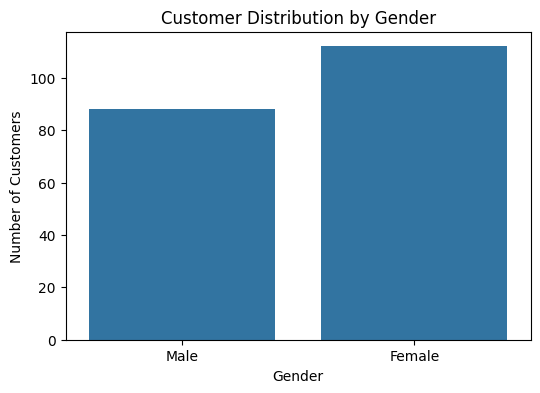

In [66]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Gender")

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

AGE DISTRIBUTION

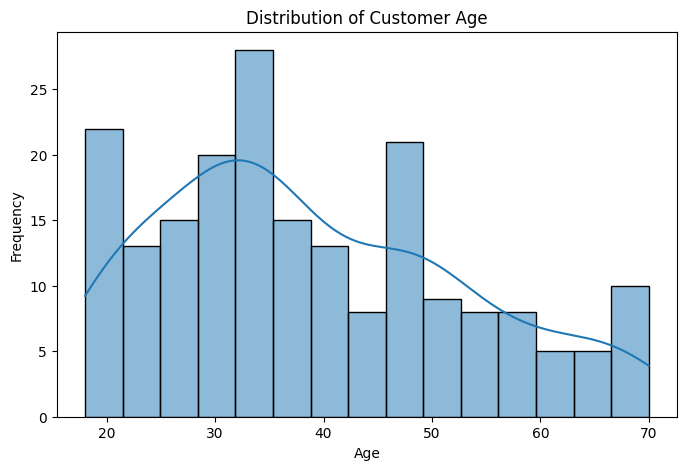

In [67]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=15, kde=True)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

ANNUAL INCOME DISTRIBUTION

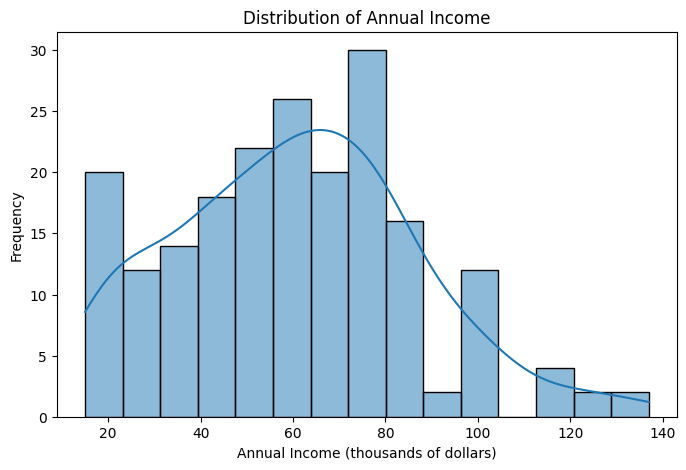

In [68]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Annual Income (k$)",
    bins=15,
    kde=True
)

plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Frequency")

plt.show()

AGE VS SPENDING

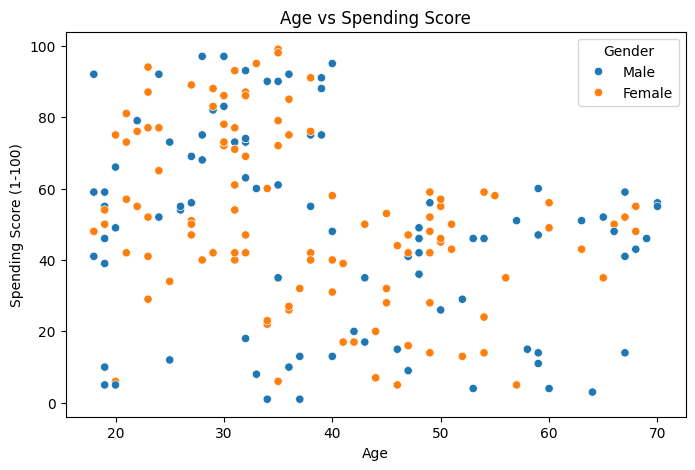

In [69]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Spending Score (1-100)",
    hue="Gender"
)

plt.title("Age vs Spending Score")
plt.show()

ANNUAL INCOME VS SPENDING SCORE

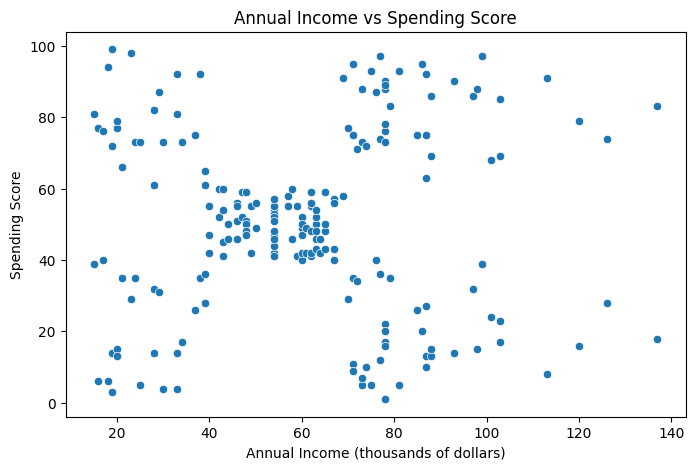

In [70]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)"
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Spending Score")

plt.show()

CORRELATION HEATMAP

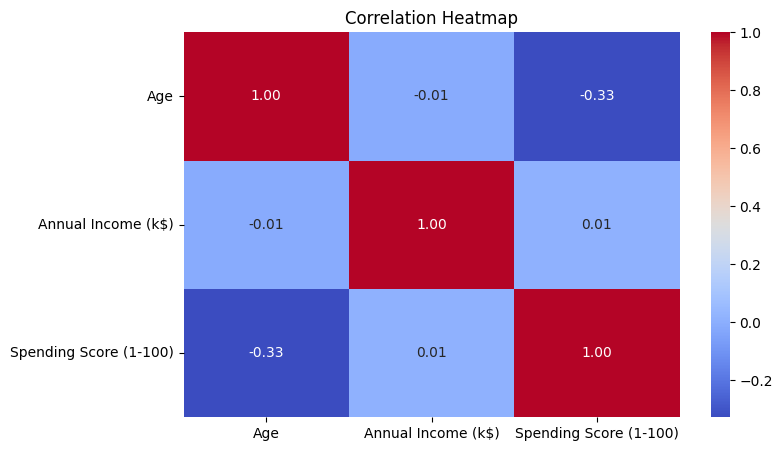

In [71]:
plt.figure(figsize=(8, 5))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.drop(columns=["CustomerID"], errors="ignore").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [72]:
features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

x = df[features]

print(x.head())

   Age  Annual Income (k$)  Spending Score (1-100)
0   19                  15                      39
1   21                  15                      81
2   20                  16                       6
3   23                  16                      77
4   31                  17                      40


In [73]:
scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

print(x_scaled[:5])

[[-1.42456879 -1.73899919 -0.43480148]
 [-1.28103541 -1.73899919  1.19570407]
 [-1.3528021  -1.70082976 -1.71591298]
 [-1.13750203 -1.70082976  1.04041783]
 [-0.56336851 -1.66266033 -0.39597992]]


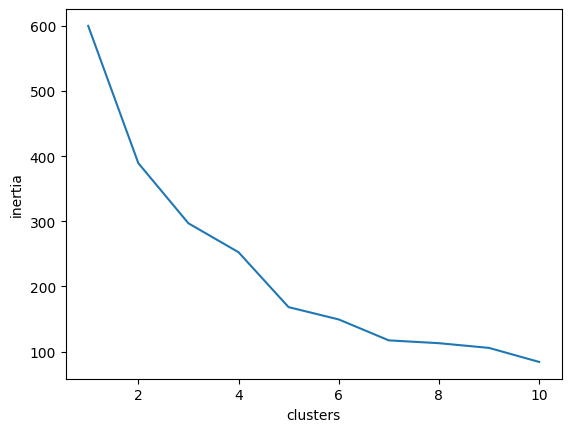

In [74]:
import matplotlib.pyplot as plt
plt.plot(range(1,11),wcss)
plt.xlabel('clusters')
plt.ylabel('inertia')
plt.show()

K = 2 | Silhouette Score = 0.3355
K = 3 | Silhouette Score = 0.3578
K = 4 | Silhouette Score = 0.404
K = 5 | Silhouette Score = 0.4166
K = 6 | Silhouette Score = 0.4284
K = 7 | Silhouette Score = 0.4172
K = 8 | Silhouette Score = 0.4082
K = 9 | Silhouette Score = 0.4177
K = 10 | Silhouette Score = 0.4066


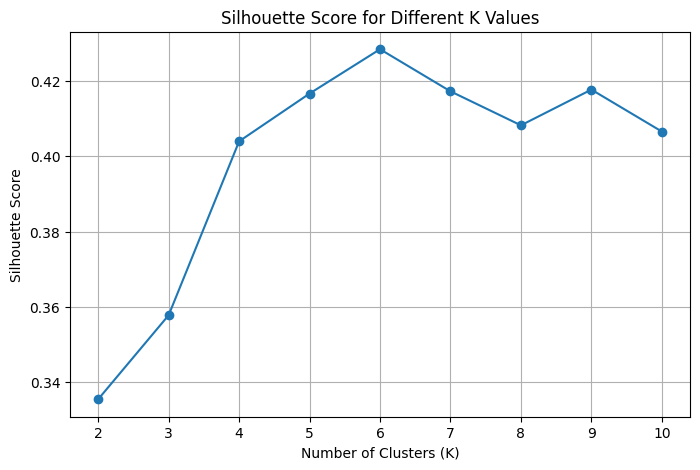

In [75]:
silhouette_values = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(x_scaled)

    score = silhouette_score(x_scaled, labels)

    silhouette_values.append(score)

    print(
        "K =", k,
        "| Silhouette Score =", round(score, 4)
    )

# Plot scores
plt.figure(figsize=(8, 5))

plt.plot(
    list(range(2, 11)),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [76]:
optimal_k = 6

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Train model and assign clusters
df["Cluster"] = kmeans.fit_predict(x_scaled)

print(df[[
    "CustomerID",
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)",
    "Cluster"
]].head(10))

   CustomerID  Age  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1   19                  15                      39        4
1           2   21                  15                      81        4
2           3   20                  16                       6        5
3           4   23                  16                      77        4
4           5   31                  17                      40        5
5           6   22                  17                      76        4
6           7   35                  18                       6        5
7           8   23                  18                      94        4
8           9   64                  19                       3        5
9          10   30                  19                      72        4


VISUAL OF CUSTOMER SEGMENTATION

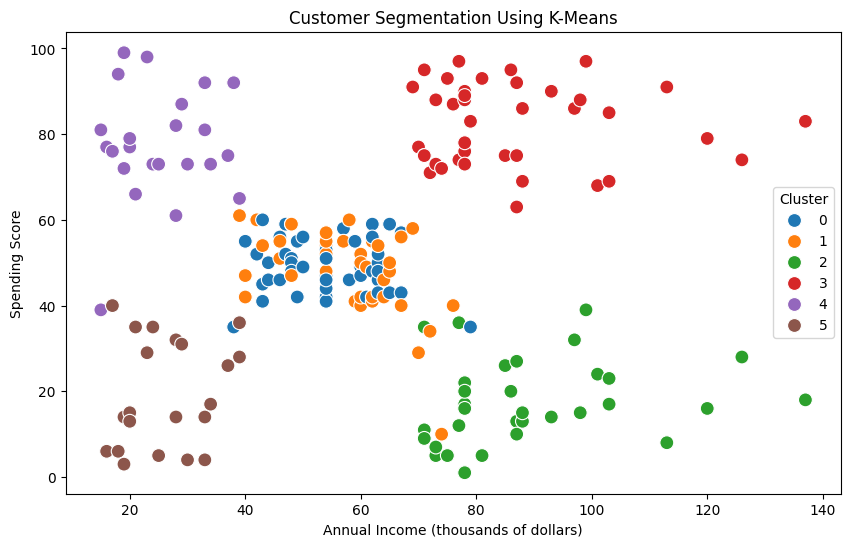

In [77]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=100
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Spending Score")

plt.legend(title="Cluster")

plt.show()

AGE VS SPENDING SCORE (CLUSTER)

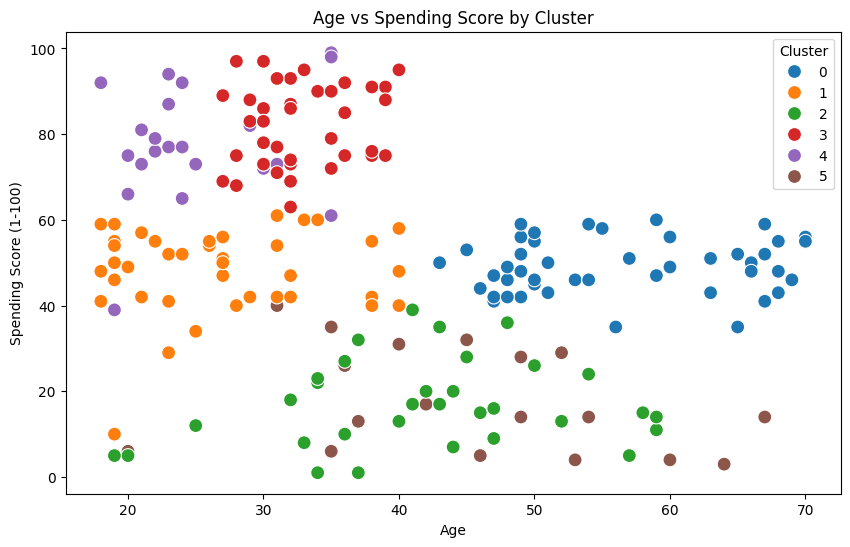

In [78]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=100
)

plt.title("Age vs Spending Score by Cluster")

plt.show()

In [79]:
cluster_profile = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)

print(cluster_profile)

         Customer_Count  Average_Age  Average_Income  Average_Spending
Cluster                                                               
0                    45        56.33           54.27             49.07
1                    39        26.79           57.10             48.13
2                    33        41.94           88.94             16.97
3                    39        32.69           86.54             82.13
4                    23        25.00           25.26             77.61
5                    21        45.52           26.29             19.38


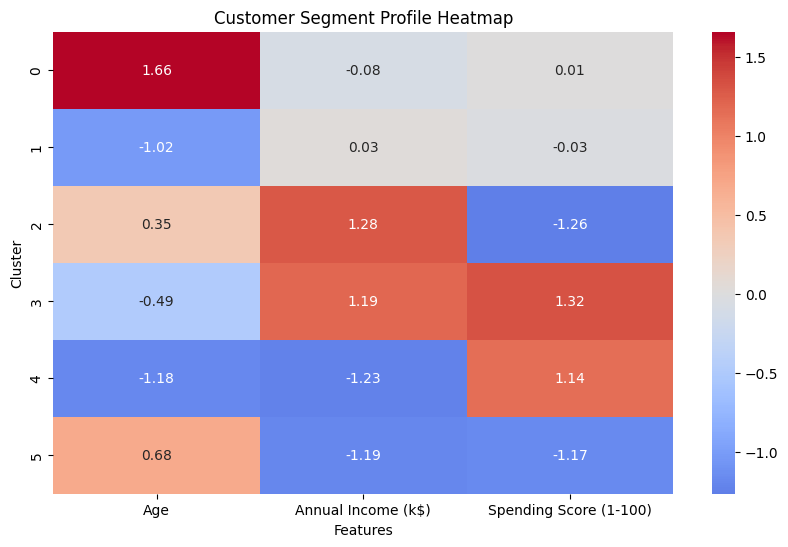

In [80]:
profile_features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

cluster_means = df.groupby("Cluster")[profile_features].mean()

# Standardize cluster averages for comparison
cluster_means_scaled = (
    cluster_means - cluster_means.mean()
) / cluster_means.std(ddof=0)

plt.figure(figsize=(10, 6))

sns.heatmap(
    cluster_means_scaled,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Customer Segment Profile Heatmap")
plt.xlabel("Features")
plt.ylabel("Cluster")

plt.show()